# Final Archetypal Analysis Plots


This notebook consolidates publication-ready visualizations for Dog, Age, and Sample Type datasets.


For each dataset, the following plots are generated:
1. PCA (PC1 vs PC2 vs PC3)
2. Davies-Bouldin + Silhouette vs number of archetypes
3. Archetypal Analysis simplex
4. Similarity degree stacked bar plot
5. Taxa contribution bar plot

## Plotters

In [23]:
%load_ext autoreload
%autoreload 2

import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib import cm
from archetypal_analysis.visualization.pcoa import PCoAVisualizer

from archetypal_analysis.data.loaders import ArchetypalResultLoader
from archetypal_analysis.analysis.metrics import AnalysisMetrics
from archetypal_analysis.visualization.simplex import SimplexPlotter
from archetypal_analysis.visualization.stacked_bar import StackedBarPlotter
from archetypal_analysis.visualization.composition import CompositionAnalyzer
from archetypal_analysis.utils.metadata import extract_metadata

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [24]:
ROOT = "."
EXPORT_DIR = os.path.join(ROOT, "final_plots")
Path(EXPORT_DIR).mkdir(parents=True, exist_ok=True)


def set_paper_style():
    plt.style.use("seaborn-v0_8-whitegrid")
    plt.rcParams.update(
        {
            "font.family": "serif",
            "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
            "font.size": 11,
            "axes.titlesize": 13,
            "axes.labelsize": 11,
            "axes.titleweight": "semibold",
            "legend.fontsize": 9,
            "xtick.labelsize": 9,
            "ytick.labelsize": 9,
            "figure.dpi": 300,
            "savefig.dpi": 600,
            "savefig.bbox": "tight",
            "axes.linewidth": 0.8,
            "grid.alpha": 0.22,
            "grid.linewidth": 0.5,
        }
    )


def save_current_figure(cfg, slug):
    dataset_slug = (
        cfg["title"].lower().replace(" ", "_").replace("(", "").replace(")", "")
    )
    base = os.path.join(EXPORT_DIR, f"{dataset_slug}_{slug}")
    plt.savefig(base + ".png")
    plt.savefig(base + ".pdf")


def read_table_auto(path):
    if path.endswith(".tsv"):
        return pd.read_table(path, index_col=0)
    return pd.read_csv(path, index_col=0)


def result_path(result_dir, k):
    return os.path.join(result_dir, f"otu_AA_K{k}_1.0_None_jensenshannon.json")


def build_uniform_archetype_colors(k):
    return {f"Archetype {i+1}": (i + 1) / max(k, 1) for i in range(k)}


def resolve_archetype_color(color_value, cmap, default=0.5):
    if isinstance(color_value, (int, float, np.integer, np.floating)):
        return cmap(float(color_value))
    if color_value is None:
        return cmap(default)
    return color_value


def reorder_similarity_and_archetypes(otu_aa, aa_archetypes, order_cols=None):
    if order_cols is None:
        return otu_aa.copy(), np.array(aa_archetypes)
    reordered = otu_aa[order_cols].copy()
    renamed_cols = [f"Archetype {i+1}" for i in range(len(order_cols))]
    reordered.columns = renamed_cols
    idx = [int(c.split()[-1]) - 1 for c in order_cols]
    aa_reordered = np.array(aa_archetypes)[idx, :]
    return reordered, aa_reordered


def build_metadata_for_samples(
    sample_index, meta, metadata_col, tags=None, projects=None
):
    out = pd.DataFrame(index=sample_index)
    # Hadza/Dog style: metadata column exists directly in sample table.
    if metadata_col in meta.columns:
        meta_local = meta.copy()
        if not meta_local.index.is_unique:
            meta_local = meta_local[~meta_local.index.duplicated(keep="first")]
        out[metadata_col] = meta_local.reindex(sample_index)[metadata_col]
        return out
    # Compendium style fallback using project/srr tags.
    if ("project" in meta.columns) and ("srr" in meta.columns):
        meta_local = meta.copy()
        meta_local["sample"] = (
            meta_local["project"].astype(str) + "_" + meta_local["srr"].astype(str)
        )
        if not meta_local["sample"].is_unique:
            meta_local = meta_local.drop_duplicates(subset="sample", keep="first")
        meta_local = meta_local.set_index("sample")
        if metadata_col in meta_local.columns:
            out[metadata_col] = meta_local.reindex(sample_index)[metadata_col]
            return out
    # Compendium project-level metadata (e.g., sample_type in projects.csv).
    if (projects is not None) and (metadata_col in projects.columns):
        projects_local = projects.copy()
        if not projects_local.index.is_unique:
            projects_local = projects_local[
                ~projects_local.index.duplicated(keep="first")
            ]
        out[metadata_col] = [
            (
                projects_local.loc[s.split("_")[0], metadata_col]
                if (isinstance(s, str) and s.split("_")[0] in projects_local.index)
                else np.nan
            )
            for s in sample_index
        ]
        return out
    # Compendium tag-level metadata (project+srr keyed long table).
    if (tags is not None) and set(["project", "srr", "tag", "value"]).issubset(
        tags.columns
    ):
        tag_rows = tags[tags["tag"] == metadata_col].copy()
        if len(tag_rows) > 0:
            tag_rows["sample"] = (
                tag_rows["project"].astype(str) + "_" + tag_rows["srr"].astype(str)
            )
            if not tag_rows["sample"].is_unique:
                tag_rows = tag_rows.drop_duplicates(subset="sample", keep="first")
            tag_map = tag_rows.set_index("sample")["value"]
            out[metadata_col] = tag_map.reindex(sample_index)
            return out
    # Last-resort fill to keep plotting code stable.
    out[metadata_col] = np.nan
    return out


def load_dataset_bundle(cfg):
    loader = ArchetypalResultLoader()
    otu = read_table_auto(cfg["otu_file"])
    meta = read_table_auto(cfg["meta_file"])
    projects = None
    tags = None
    if cfg.get("projects_file"):
        projects = pd.read_csv(cfg["projects_file"], index_col=0)
    if cfg.get("tags_file"):
        tags = pd.read_table(cfg["tags_file"], index_col=0)
    otu_aa, aa_labels, aa_archetypes, info = loader.load_parsed_result(
        result_path(cfg["result_dir"], cfg["main_k"])
    )
    otu_aa, aa_archetypes = reorder_similarity_and_archetypes(
        otu_aa, aa_archetypes, cfg.get("archetype_order")
    )
    metadata = build_metadata_for_samples(
        sample_index=otu_aa.index,
        meta=meta,
        metadata_col=cfg["metadata_col"],
        tags=tags,
        projects=projects,
    )
    return {
        "otu": otu,
        "meta": meta,
        "projects": projects,
        "tags": tags,
        "otu_aa": otu_aa,
        "aa_labels": aa_labels,
        "aa_archetypes": aa_archetypes,
        "info": info,
        "metadata": metadata,
    }


def plot_pcoa_panel(otu, aa_archetypes, metadata, cfg):
    pcoa_visualizer = PCoAVisualizer()
    arch_df = pd.DataFrame(
        aa_archetypes,
        columns=otu.columns,
        index=[f"Archetype {i+1}" for i in range(len(aa_archetypes))],
    )
    otu_with_archs = pd.concat([otu, arch_df], axis=0)
    pcoa_coords, pcoa_results = pcoa_visualizer.create_pcoa_from_otu(
        otu_data=otu_with_archs,
        distance_metric="jensenshannon",
        n_dimensions=3,
        apply_log_transform=True,
        clean_data=True,
        verbose=False,
    )
    fig, axs = pcoa_visualizer.plot_pcoa(
        pcoa_coordinates=pcoa_coords,
        pcoa_results=pcoa_results,
        metadata=metadata,
        filter_col=cfg["metadata_col"],
        legend_type=cfg["legend_type"],
        figsize=(9.5, 4.9),
        alpha=0.72,
        s=18,
        pc_combinations=[("PC1", "PC2"), ("PC2", "PC3")],  # ('PC1', 'PC3')],
        cmap_name=cfg["cmap"],
    )
    arch_coords = pcoa_coords.loc[arch_df.index]
    arch_cmap = cm.get_cmap(cfg["cmap"])
    arch_color_map = cfg["archetype_colors"]
    for ax, (x_pc, y_pc) in zip(axs, [("PC1", "PC2"), ("PC2", "PC3")]):
        for arch_name, row in arch_coords.iterrows():
            ax.scatter(
                row[x_pc],
                row[y_pc],
                marker="X",
                s=275,
                color=resolve_archetype_color(
                    arch_color_map.get(arch_name, None), arch_cmap, default=0.5
                ),
                edgecolor="black",
                linewidth=0.7,
                zorder=5,
            )
            # ax.text(row[x_pc], row[y_pc], arch_name, fontsize=8)
    # Bold font
    fig.suptitle(f"{cfg['title']}: PCoA Component Comparisons", y=1.02, fontweight="semibold")
    plt.tight_layout()
    save_current_figure(cfg, "pcoa_panel")
    plt.show()


def plot_scores_vs_k(cfg, metadata, loader):
    k_values = cfg["k_values"]
    results = loader.load_multiple_results(
        k_values=k_values, directory=cfg["result_dir"]
    )
    metrics = AnalysisMetrics()
    comp = metrics.compare_archetype_quality(
        results_dict=results,
        metadata=metadata,
        metadata_column=cfg["metadata_col"],
        discretize=cfg.get("discretize_scores", False),
        buckets=cfg.get("score_buckets", None),
        metrics=["silhouette", "davies_bouldin"],
    )
    fig, ax1 = plt.subplots(figsize=(8.8, 4.9))
    ax2 = ax1.twinx()
    ax1.plot(
        comp["k"],
        comp["silhouette"],
        color="#1f77b4",
        marker="o",
        linewidth=2,
        label="Silhouette",
    )
    ax2.plot(
        comp["k"],
        comp["davies_bouldin"],
        color="#d62728",
        marker="s",
        linewidth=2,
        label="Davies-Bouldin",
    )
    ax1.set_xlabel("Number of archetypes (K)")
    ax1.set_ylabel("Silhouette score", color="#1f77b4")
    ax2.set_ylabel("Davies-Bouldin score", color="#d62728")
    ax1.set_title(
        f"{cfg['title']}: Davies-Bouldin + Silhouette vs Number of Archetypes"
    )
    ax1.grid(True, alpha=0.25)
    lines = ax1.get_lines() + ax2.get_lines()
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc="best", frameon=True)
    plt.tight_layout()
    save_current_figure(cfg, "scores_vs_k")
    plt.show()


def plot_simplex_panel(otu_aa, metadata, cfg):
    simplex_plotter = SimplexPlotter()
    plot_metadata = metadata.copy()
    discrete_key_cmap = None
    key_to_color_idx = None
    key_color_map = cfg.get("key_color_map", None)
    if key_color_map is None:
        # Backward compatibility for configs where key_color_map was nested.
        key_color_map = cfg.get("label_rename_map", {}).get("key_color_map", None)
    if cfg["legend_type"] == "discrete":
        col = cfg["metadata_col"]
        mask = plot_metadata[col].notna()
        plot_metadata.loc[mask, col] = (
            plot_metadata.loc[mask, col]
            .astype(str)
            .str.replace(r"^\s*\d+\s*[\.\):-]?\s*", "", regex=True)
            .str.strip()
        )
        rename_map = cfg.get("label_rename_map", None)
        if rename_map:
            plot_metadata.loc[mask, col] = plot_metadata.loc[mask, col].map(
                lambda x: rename_map.get(x, x)
            )
        if key_color_map:
            from matplotlib.colors import ListedColormap

            labels_for_colors = [
                lbl
                for lbl in sorted(
                    plot_metadata[cfg["metadata_col"]].dropna().unique(),
                    key=lambda x: str(x),
                )
            ]
            if len(labels_for_colors) > 0:
                fallback_cmap = cm.get_cmap(cfg["cmap"], len(labels_for_colors))
                color_list = [
                    key_color_map.get(lbl, fallback_cmap(i))
                    for i, lbl in enumerate(labels_for_colors)
                ]
                discrete_key_cmap = ListedColormap(color_list)
                key_to_color_idx = {lbl: i for i, lbl in enumerate(labels_for_colors)}
    simplex_plotter.plot_simplex(
        otu_aa=otu_aa,
        metadata=plot_metadata,
        filter_cols=[cfg["metadata_col"]],
        cmap_name=discrete_key_cmap if discrete_key_cmap is not None else cfg["cmap"],
        legend_type=cfg["legend_type"],
        remove_nan=True,
        alpha=0.76,
        s=30,
        figsize=(8.7, 8.0),
        remove_values=cfg.get("remove_values", {}),
        legend_fontsize=9,
        custom_colors=key_to_color_idx if key_to_color_idx is not None else None,
        show_direction=False,
        direction_alpha=0,
    )
    if cfg["legend_type"] == "continuous":
        vals = pd.to_numeric(plot_metadata[cfg["metadata_col"]], errors="coerce")
        vals = vals[np.isfinite(vals)]
        if len(vals) > 0 and len(plt.gcf().axes) > 1:
            min_val = float(np.nanmin(vals))
            max_val = float(np.nanmax(vals))
            tick_min = int(np.rint(min_val))
            tick_max = int(np.rint(max_val))
            if tick_min > tick_max:
                tick_min, tick_max = tick_max, tick_min
            if tick_min == tick_max:
                tick_vals = np.array([tick_min], dtype=int)
            else:
                n_intervals = min(6, tick_max - tick_min)
                raw_ticks = np.linspace(tick_min, tick_max, n_intervals + 1)
                tick_vals = np.unique(np.rint(raw_ticks).astype(int))
                if tick_vals[0] != tick_min:
                    tick_vals = np.insert(tick_vals, 0, tick_min)
                if tick_vals[-1] != tick_max:
                    tick_vals = np.append(tick_vals, tick_max)
            cax = plt.gcf().axes[-1]
            cax.set_yticks(tick_vals)
            cax.set_yticklabels([f"{int(v)}" for v in tick_vals])
            cax.set_ylabel(cfg.get("colorbar_title", cfg["metadata_col"]))
    plt.title(f"{cfg['title']}: Archetypal Analysis Simplex")
    plt.tight_layout()
    save_current_figure(cfg, "simplex")
    plt.show()


def plot_similarity_stacked(otu_aa, info, metadata, cfg):
    stacked = StackedBarPlotter()
    stacked.plot_metadata_stacked_bars(
        similarity_degree=otu_aa,
        metadata=metadata,
        perms=info.get("perms", None),
        metadata_column=cfg["metadata_col"],
        discretize=cfg.get("discretize_stacked", False),
        buckets=cfg.get("stacked_buckets", None),
        cmap_name=cfg["cmap"],
        vertex_colors=cfg["archetype_colors"],
        figsize=(11.6, 4.0),
        alpha=0.9,
    )
    plt.title(f"{cfg['title']}: Similarity Degree Stacked Bar")
    plt.tight_layout()
    save_current_figure(cfg, "stacked_bar")
    plt.show()


def plot_taxa_contribution(otu, aa_archetypes, cfg):
    comp = CompositionAnalyzer()
    top_taxa = comp.analyze_top_taxa(
        archetypes=np.array(aa_archetypes),
        feature_names=otu.columns,
        num_taxa=cfg.get("num_taxa", 5),
    )

    comp.plot_stacked_bar_chart(
        aa_archetypes=np.array(aa_archetypes),
        feature_names=otu.columns,
        top_taxa_archetypes=top_taxa,
        figsize=(10.8, 5.9),
        sort_by_contribution=True,
        simplify_names=True,
        max_name_length=18,
    )
    plt.title(f"{cfg['title']}: Taxa Contribution Bar Plot")
    plt.tight_layout()
    save_current_figure(cfg, "taxa_contribution")
    plt.show()


def run_all_plots_for_dataset(cfg):
    set_paper_style()
    loader = ArchetypalResultLoader()
    bundle = load_dataset_bundle(cfg)

    plot_pcoa_panel(bundle["otu"], bundle["aa_archetypes"], bundle["metadata"], cfg)
    plot_scores_vs_k(cfg, bundle["metadata"], loader)
    plot_simplex_panel(bundle["otu_aa"], bundle["metadata"], cfg)
    plot_similarity_stacked(bundle["otu_aa"], bundle["info"], bundle["metadata"], cfg)
    plot_taxa_contribution(bundle["otu"], bundle["aa_archetypes"], cfg)


DATASET_CONFIGS_PATH = os.path.join(ROOT, "dataset_configs.json")


def load_dataset_configs(path=DATASET_CONFIGS_PATH):
    with open(path, "r") as f:
        return json.load(f)


DATASET_CONFIGS = load_dataset_configs()


print("Plotters ready. Figures will also be exported to:", EXPORT_DIR)

Plotters ready. Figures will also be exported to: ./final_plots


## Dog Dataset Results

/var/folders/px/v6h_m_713lg54rd8cj7pmkz00000gn/T/ipykernel_81146/839164312.py:194: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  arch_cmap = cm.get_cmap(cfg["cmap"])


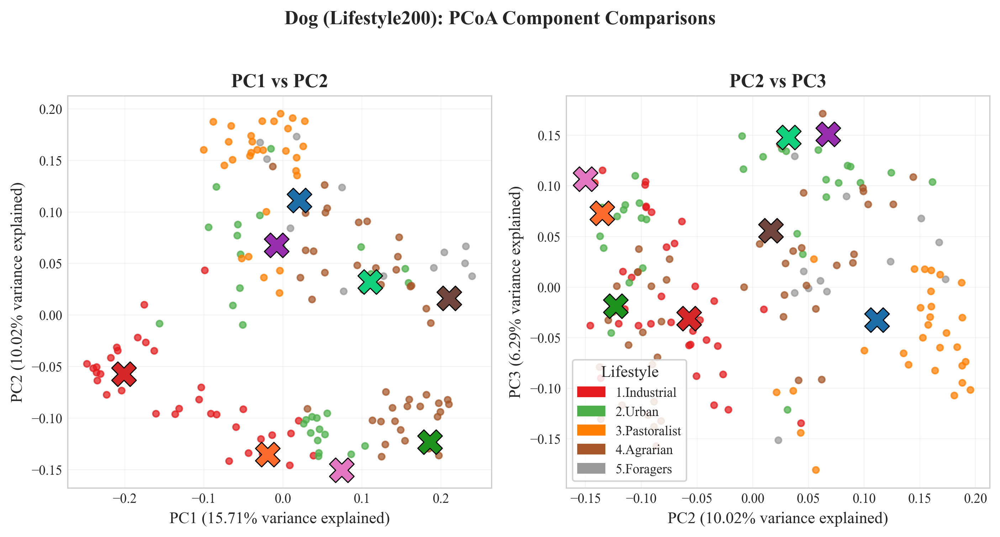

Evaluating K: 100%|██████████| 11/11 [00:00<00:00, 645.92it/s]


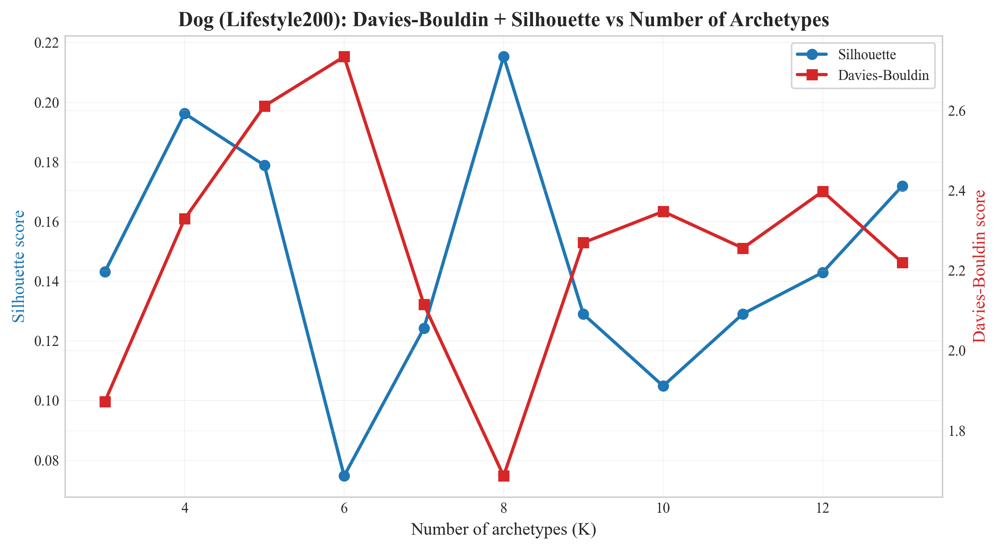

/var/folders/px/v6h_m_713lg54rd8cj7pmkz00000gn/T/ipykernel_81146/839164312.py:299: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  fallback_cmap = cm.get_cmap(cfg["cmap"], len(labels_for_colors))


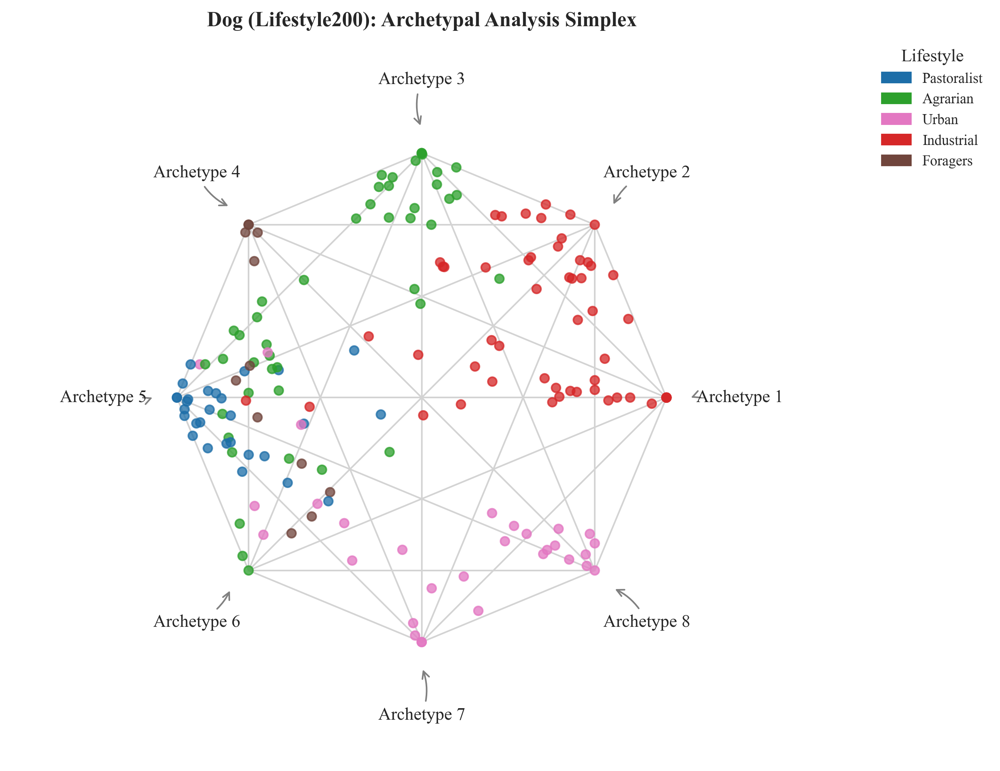

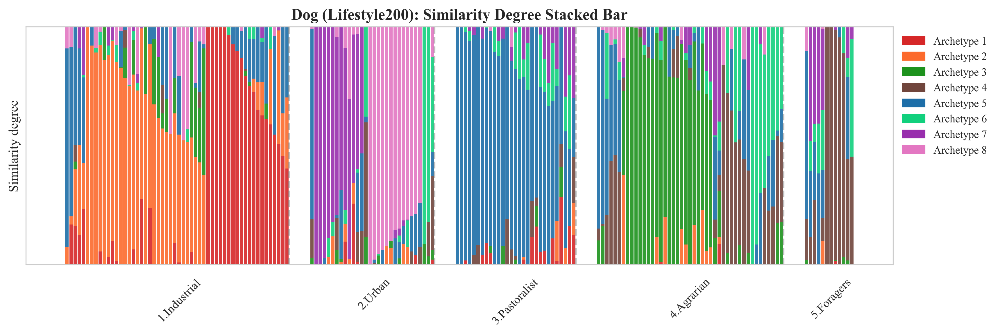

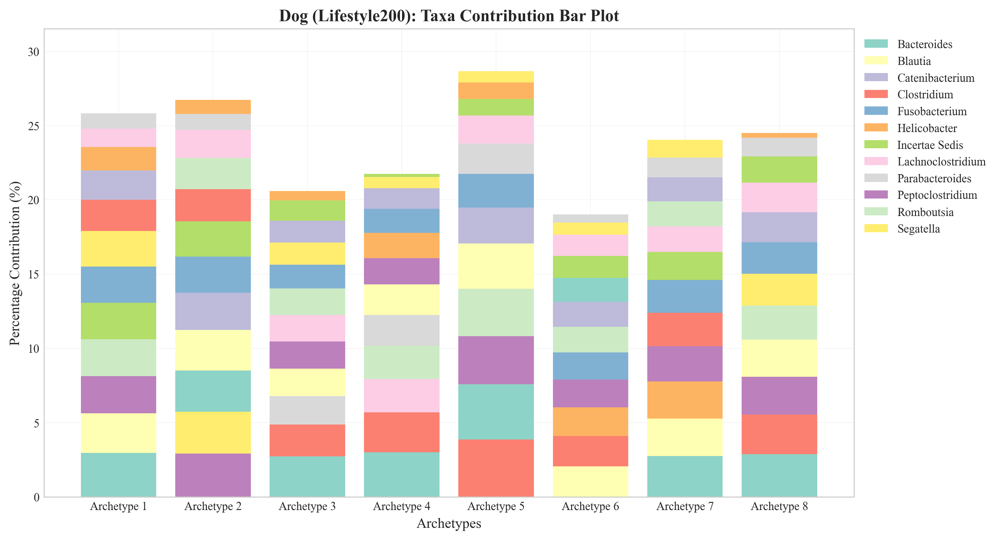

In [25]:
run_all_plots_for_dataset(DATASET_CONFIGS['dog'])

## Age Dataset Results

/var/folders/px/v6h_m_713lg54rd8cj7pmkz00000gn/T/ipykernel_81146/839164312.py:40: DtypeWarning: Columns (0: AGE_MONTHS, 1: SUBJECT_ID, 2: Sample, 3: Age, 4: GENDER, 5: AGE, 6: BREASTFEEDING, 7: RECALL_72H.BAOBAB, 8: RECALL_72H.BERRIES, 9: RECALL_72H.HONEY, 10: RECALL_72H.MAIZE, 11: RECALL_72H.MEAT, 12: RECALL_72H.MILLET, 13: RECALL_72H.TUBERS, 14: RECALL_PRIMARY_FOOD_72H, 15: SLEEPS_WITH_MOTHER, 16: WATER_SOURCE, 17: WEIGHT_KGS, 18: BMI, 19: TWO_SEASON, 20: FOUR_SEASON_YEAR, 21: TWO_SEASON_YEAR, 22: gest_time, 23: Exclusive_breast_feeding, 24: Breast_feeding_end, 25: Regular_formula, 26: hydrosylated_formula, 27: partly_hydrosylated_formula, 28: Any_baby_formula, 29: Fruits_and_berries, 30: Corn, 31: Rice, 32: Wheat, 33: Oat, 34: Barley, 35: Rye, 36: Cereal, 37: Other_grains, 38: Root_vegetables, 39: Vegetables, 40: Eggs, 41: Soy, 42: Milk, 43: Meat, 44: Fish, 45: Other_food, 46: Other_than_BF, 47: bf_length, 48: after_abx, 49: num_preceeding_abx, 50: num_aabs, 51: allergy_egg, 52: all

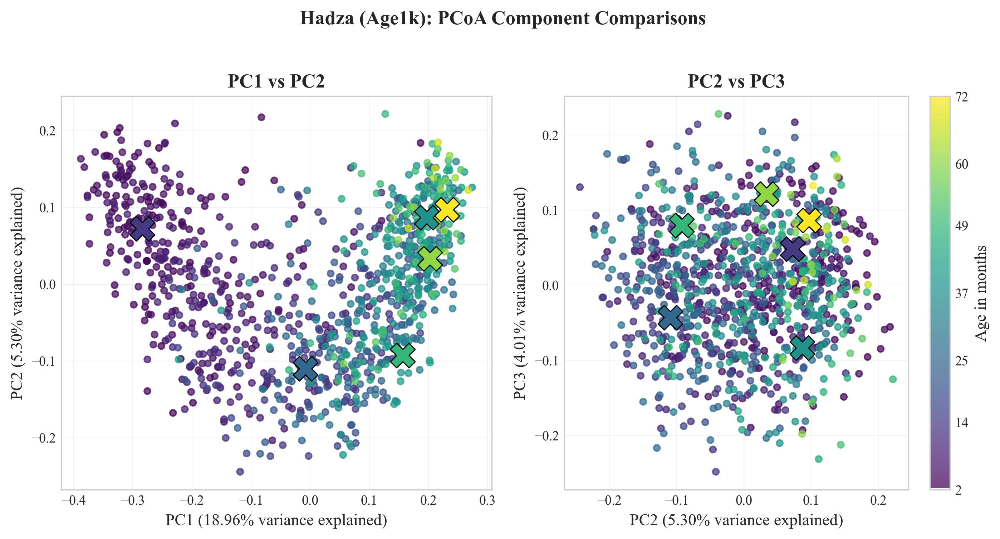

Evaluating K: 100%|██████████| 11/11 [00:00<00:00, 57.48it/s]


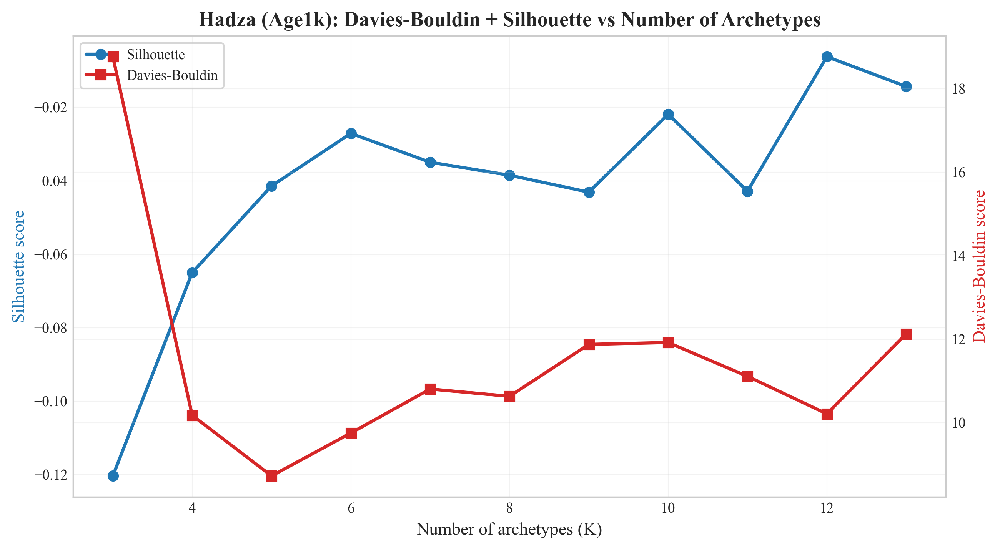

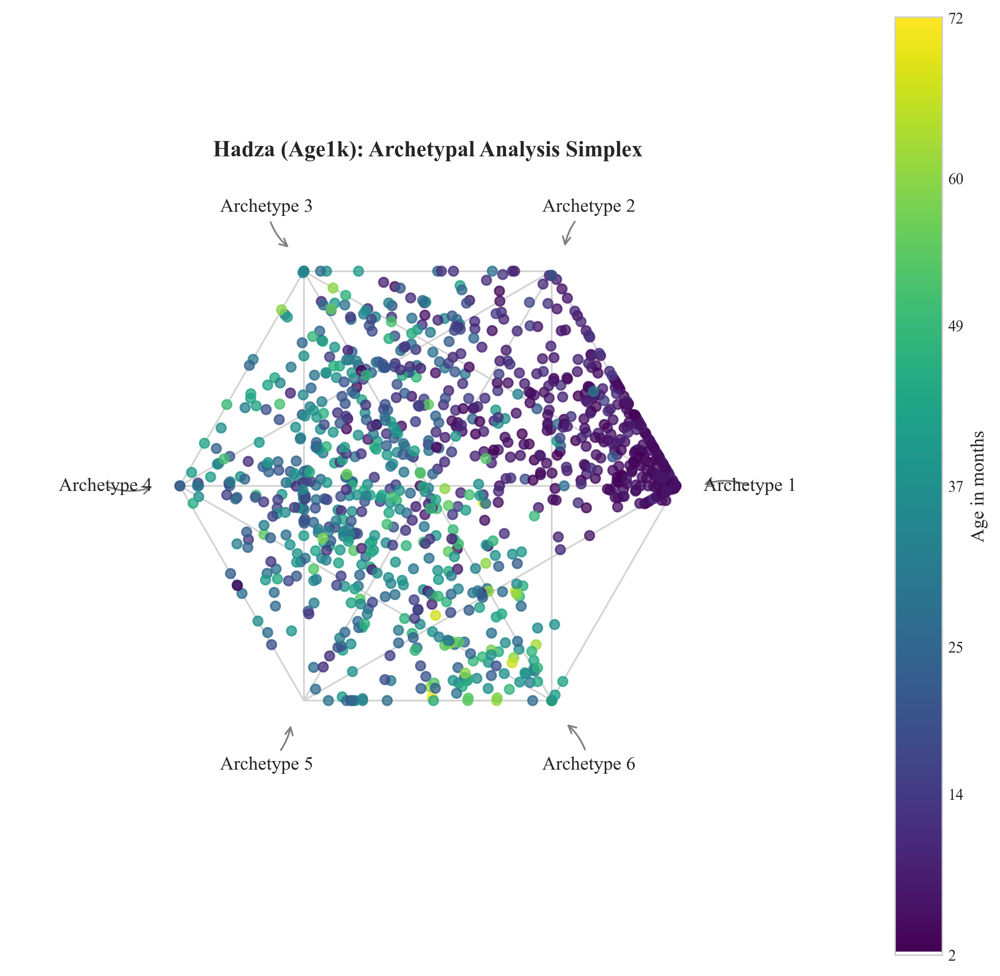

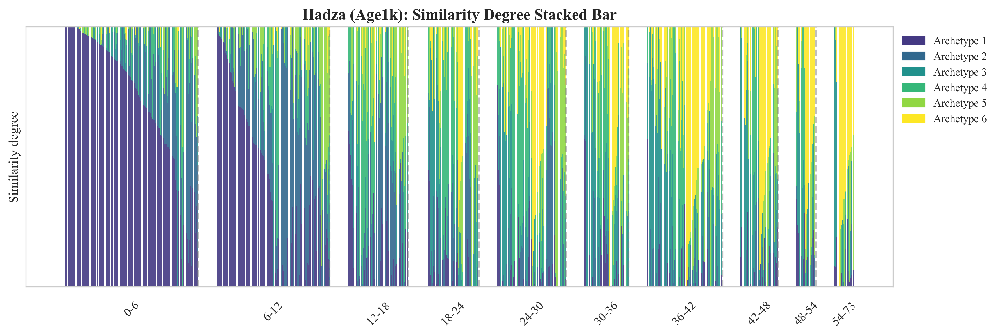

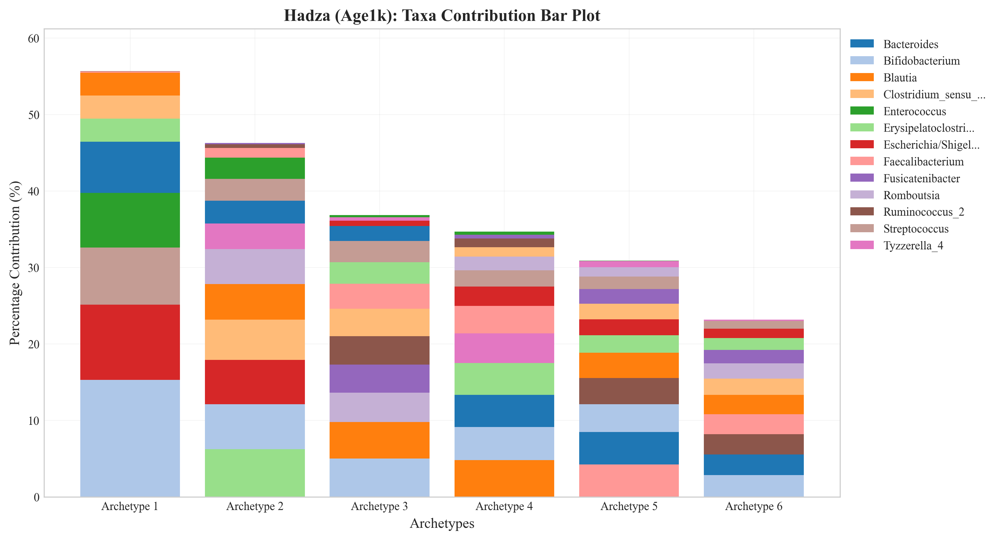

In [26]:
run_all_plots_for_dataset(DATASET_CONFIGS['age'])

## Sample Type Dataset Results (Updated)

/var/folders/px/v6h_m_713lg54rd8cj7pmkz00000gn/T/ipykernel_81146/839164312.py:194: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  arch_cmap = cm.get_cmap(cfg["cmap"])


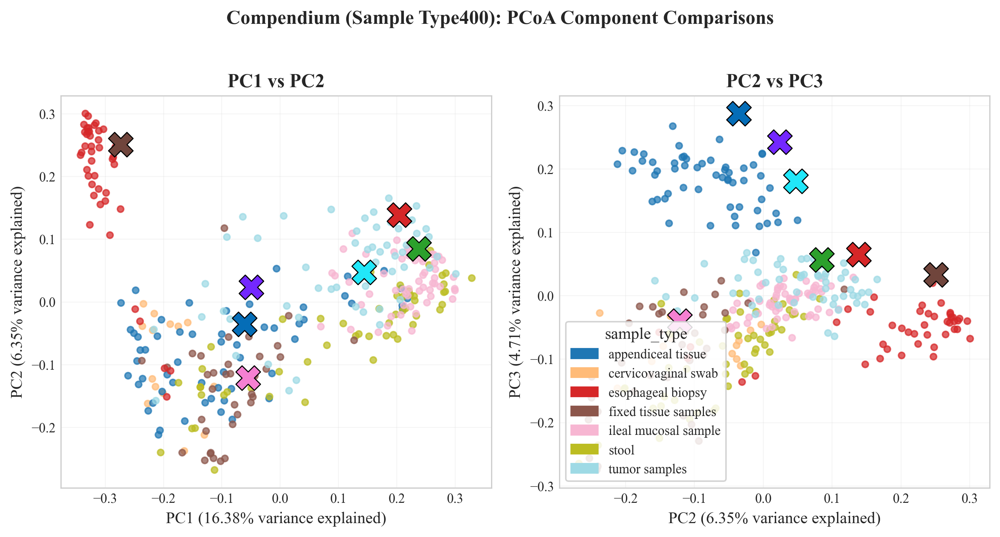

Evaluating K: 100%|██████████| 11/11 [00:00<00:00, 328.01it/s]


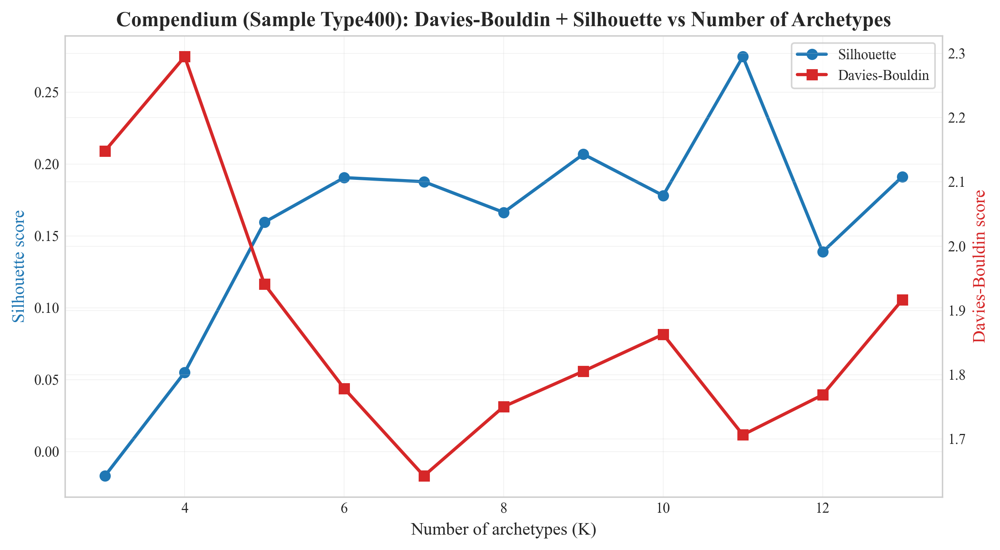

/var/folders/px/v6h_m_713lg54rd8cj7pmkz00000gn/T/ipykernel_81146/839164312.py:299: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  fallback_cmap = cm.get_cmap(cfg["cmap"], len(labels_for_colors))


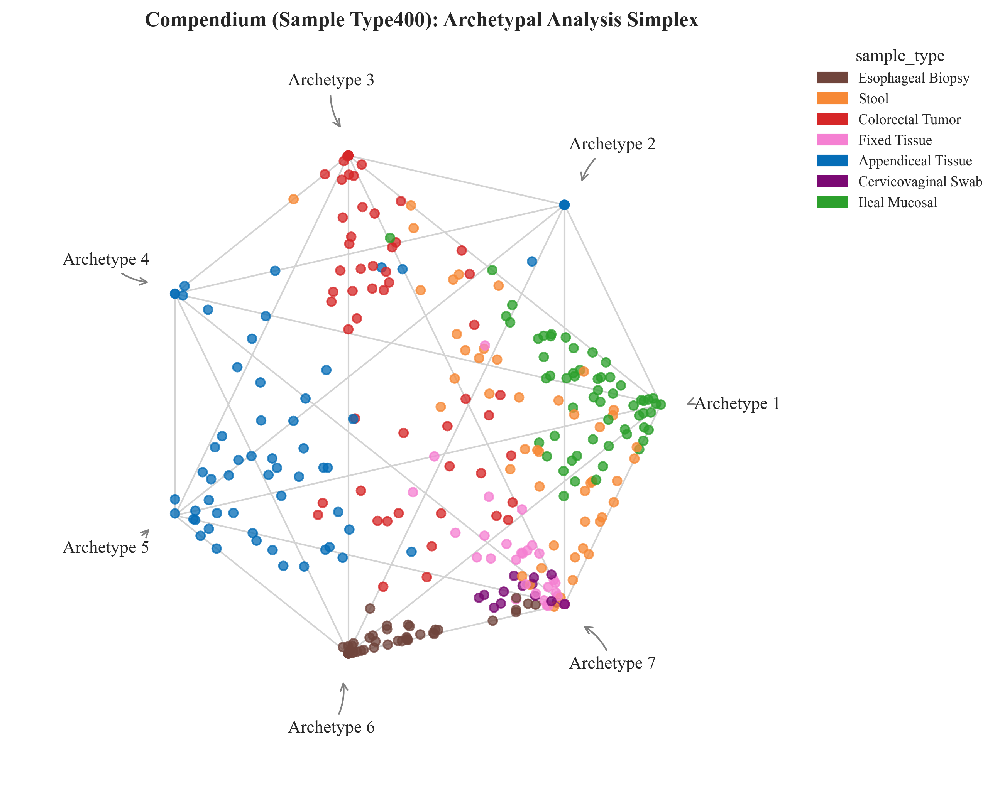

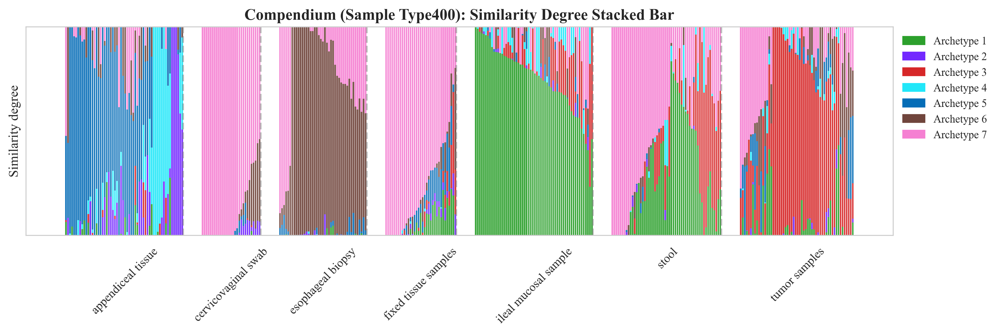

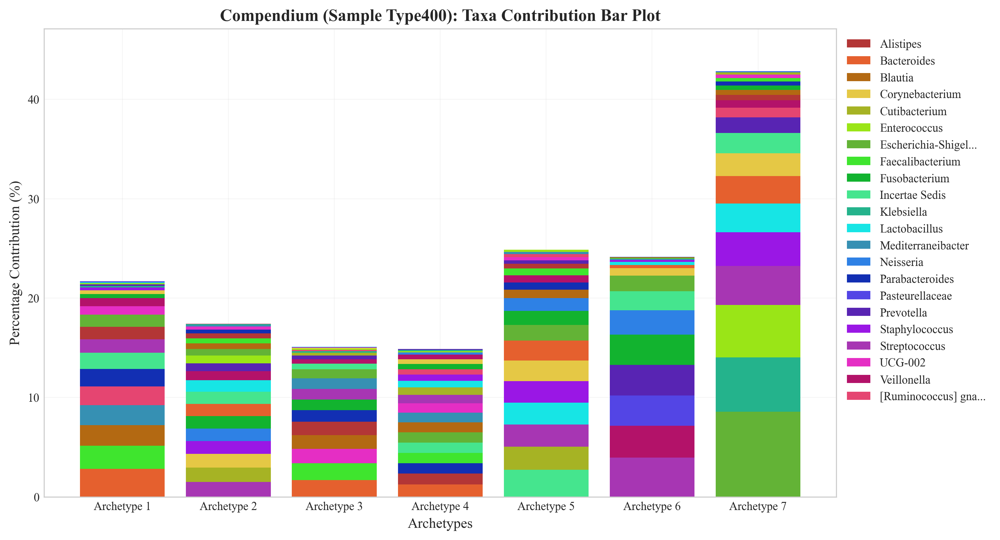

In [27]:
run_all_plots_for_dataset(DATASET_CONFIGS['sample_type'])

## Consolidated Multi-Panel Figure
Build a single asymmetric figure with:
- Top-left: Archetype simplex
- Top-right: Similarity degree stacked bar
- Bottom-left: PCoA (PC1 vs PC2 and PC2 vs PC3)
- Bottom-right: Taxa contribution




Use `CONSOLIDATED_LAYOUT_DEFAULTS` (or your own `layout_cfg`) to tune relative dimensions and spacing.

In [28]:
def _integer_ticks_with_intermediates(min_val, max_val, max_intervals=6):
    tick_min = int(np.rint(min_val))
    tick_max = int(np.rint(max_val))
    if tick_min > tick_max:
        tick_min, tick_max = tick_max, tick_min
    if tick_min == tick_max:
        return np.array([tick_min], dtype=int)
    n_intervals = min(max_intervals, tick_max - tick_min)
    raw_ticks = np.linspace(tick_min, tick_max, n_intervals + 1)
    tick_vals = np.unique(np.rint(raw_ticks).astype(int))
    if tick_vals[0] != tick_min:
        tick_vals = np.insert(tick_vals, 0, tick_min)
    if tick_vals[-1] != tick_max:
        tick_vals = np.append(tick_vals, tick_max)
    return tick_vals
def _plot_taxa_contribution_on_axis(ax, otu, aa_archetypes, cfg):

    comp = CompositionAnalyzer()
    num_taxa = cfg.get("num_taxa", 5)
    arch_array = np.array(aa_archetypes)
    archetype_names = [f"Archetype {i+1}" for i in range(len(arch_array))]
    top_taxa = comp.analyze_top_taxa(
        archetypes=arch_array,
        feature_names=otu.columns,
        archetype_names=archetype_names,
        num_taxa=num_taxa,
    )
    all_top_taxa = set()
    for arch_data in top_taxa:
        for _, taxa in arch_data[:-1]:
            all_top_taxa.add(taxa)
    all_top_taxa = sorted(list(all_top_taxa))
    simplified_mapping = comp.simplify_taxa_names(all_top_taxa, max_length=18)
    all_top_taxa = sorted(all_top_taxa, key=lambda x: simplified_mapping[x])
    arch_df = pd.DataFrame(arch_array, columns=otu.columns, index=archetype_names)
    taxa_percentages = comp._create_taxa_percentage_matrix(
        arch_df, all_top_taxa, archetype_names
    )
    colors = comp._generate_distinct_colors(len(all_top_taxa))
    comp._plot_stacked_bars(
        ax=ax,
        taxa_percentages=taxa_percentages,
        all_top_taxa=all_top_taxa,
        archetype_names=archetype_names,
        colors=colors,
        sort_by_contribution=True,
        simplify_names=True,
        max_name_length=18,
        simplified_mapping=simplified_mapping,
    )
    from matplotlib.patches import Patch
    legend_labels = [simplified_mapping[taxa] for taxa in all_top_taxa]
    legend_handles = [
        Patch(facecolor=colors[i], label=legend_labels[i])
        for i in range(len(legend_labels))
    ]
    sorted_pairs = sorted(zip(legend_handles, legend_labels), key=lambda x: x[1])
    sorted_handles = [h for h, _ in sorted_pairs]
    sorted_labels = [l for _, l in sorted_pairs]
    ax.legend(
        sorted_handles,
        sorted_labels,
        loc="upper left",
        bbox_to_anchor=(1.01, 1),
        fontsize=8,
    )
    ax.set_xlabel("Archetypes")
    ax.set_ylabel("Percentage Contribution (%)")
    ax.set_xticks(range(len(archetype_names)))
    ax.set_xticklabels(archetype_names)
    max_height = max(
        [
            sum([taxa_percentages[taxa][arch_idx] for taxa in all_top_taxa])
            for arch_idx in range(len(archetype_names))
        ]
    )
    ax.set_ylim(0, max_height * 1.1 if max_height > 0 else 100)
    
    
def plot_consolidated_figure(cfg, layout_cfg=None, save_figure=True):

    set_paper_style()
    bundle = load_dataset_bundle(cfg)
    plot_metadata = bundle["metadata"].copy()
    legend_title = cfg.get("legend_title", cfg["metadata_col"])
    panel_cmap = cfg.get("panel_cmap", "tab20")
    simplex_cmap = cfg.get("simplex_cmap", panel_cmap)
    similarity_cmap = cfg.get("similarity_cmap", panel_cmap)
    pcoa_cmap = cfg.get("pcoa_cmap", panel_cmap)
    key_color_map = cfg.get("key_color_map", None)
    effective_key_color_map = key_color_map
    discrete_key_cmap = None
    key_to_color_idx = None
    if cfg["legend_type"] == "discrete":
        col = cfg["metadata_col"]
        mask = plot_metadata[col].notna()
        plot_metadata.loc[mask, col] = (
            plot_metadata.loc[mask, col]
            .astype(str)
            .str.replace(r"^\s*\d+\s*[\.\):-]?\s*", "", regex=True)
            .str.strip()
        )
        rename_map = cfg.get("label_rename_map", None)
        if rename_map:
            plot_metadata.loc[mask, col] = plot_metadata.loc[mask, col].map(
                lambda x: rename_map.get(x, x)
            )
    if (effective_key_color_map is None) and cfg["legend_type"] == "discrete":
        archetype_color_values = list(cfg.get("archetype_colors", {}).values())
        if len(archetype_color_values) > 0:
            label_values = [
                lbl for lbl in sorted(plot_metadata[cfg["metadata_col"]].dropna().unique(), key=lambda x: str(x))
            ]
            cmap_for_arch = cm.get_cmap(simplex_cmap)
            effective_key_color_map = {
                lbl: resolve_archetype_color(
                    archetype_color_values[i % len(archetype_color_values)],
                    cmap_for_arch,
                    default=0.5,
                )
                for i, lbl in enumerate(label_values)
            }
    if cfg["legend_type"] == "discrete" and effective_key_color_map:
        from matplotlib.colors import ListedColormap
        labels_for_colors = [
            lbl for lbl in sorted(plot_metadata[cfg["metadata_col"]].dropna().unique(), key=lambda x: str(x))
        ]
        if len(labels_for_colors) > 0:
            fallback_cmap = cm.get_cmap(panel_cmap, len(labels_for_colors))
            color_list = [effective_key_color_map.get(lbl, fallback_cmap(i)) for i, lbl in enumerate(labels_for_colors)]
            discrete_key_cmap = ListedColormap(color_list)
            key_to_color_idx = {lbl: i for i, lbl in enumerate(labels_for_colors)}
    layout = {
        "figsize": (18, 10),
        "width_ratios": [1.0, 1.0],
        "left_height_ratios": [2.0, 1.0],
        "right_height_ratios": [1.0, 1.0],
        "wspace": 0.25,
        "left_hspace": 0.24,
        "right_hspace": 0.24,
        "pcoa_wspace": 0.30,
        "simplex_x_offset": 0.0,
        "simplex_width_scale": 1.0,
        "stacked_x_offset": -0.06,
        "stacked_width_scale": 1.22,
    }
    if layout_cfg is not None:
        layout.update(layout_cfg)
    fig = plt.figure(figsize=layout["figsize"])
    gs = fig.add_gridspec(
        1,
        2,
        width_ratios=layout["width_ratios"],
        wspace=layout["wspace"],
    )
    left_gs = gs[0, 0].subgridspec(
        2,
        1,
        height_ratios=layout["left_height_ratios"],
        hspace=layout["left_hspace"],
    )
    right_gs = gs[0, 1].subgridspec(
        2,
        1,
        height_ratios=layout["right_height_ratios"],
        hspace=layout["right_hspace"],
    )
    ax_simplex = fig.add_subplot(left_gs[0, 0])
    ax_stacked = fig.add_subplot(right_gs[0, 0])
    pcoa_gs = left_gs[1, 0].subgridspec(1, 2, wspace=layout["pcoa_wspace"])
    ax_pcoa_1 = fig.add_subplot(pcoa_gs[0, 0])
    ax_pcoa_2 = fig.add_subplot(pcoa_gs[0, 1])
    ax_taxa = fig.add_subplot(right_gs[1, 0])
    
    
    simplex_plotter = SimplexPlotter()
    n_axes_before_simplex = len(fig.axes)
    simplex_plotter.plot_simplex(
        otu_aa=bundle["otu_aa"],
        metadata=plot_metadata,
        filter_cols=[cfg["metadata_col"]],
        cmap_name=discrete_key_cmap if discrete_key_cmap is not None else simplex_cmap,
        legend_type=cfg["legend_type"],
        remove_nan=True,
        alpha=0.76,
        s=28,
        remove_values=cfg.get("remove_values", {}),
        legend_fontsize=8,
        ax=ax_simplex,
        show_direction=False,
        direction_alpha=0,
        make_arrows=False,
        custom_colors=key_to_color_idx if key_to_color_idx is not None else None,
    )
    simplex_cbar_ax = fig.axes[-1] if len(fig.axes) > n_axes_before_simplex else None
    if cfg["legend_type"] == "continuous" and simplex_cbar_ax is not None:
        vals = pd.to_numeric(plot_metadata[cfg["metadata_col"]], errors="coerce")
        vals = vals[np.isfinite(vals)]
        if len(vals) > 0:
            tick_vals = _integer_ticks_with_intermediates(
                float(np.nanmin(vals)), float(np.nanmax(vals))
            )
            simplex_cbar_ax.set_yticks(tick_vals)
            simplex_cbar_ax.set_yticklabels([f"{int(v)}" for v in tick_vals])
            simplex_cbar_ax.set_ylabel(cfg.get("colorbar_title", "Age in months"))
    simplex_pos = ax_simplex.get_position()
    ax_simplex.set_position(
        [
            simplex_pos.x0 + layout["simplex_x_offset"],
            simplex_pos.y0,
            simplex_pos.width * layout["simplex_width_scale"],
            simplex_pos.height,
        ]
    )
    if cfg["legend_type"] == "discrete":
        leg = ax_simplex.get_legend()
        if leg is not None:
            leg.set_title(legend_title)
    ax_simplex.set_title("Archetype Simplex")
    
    
    stacked = StackedBarPlotter()
    stacked.stacked_bar(
        points=bundle["otu_aa"].to_numpy(),
        perms=bundle["info"].get("perms", None),
        ax=ax_stacked,
        labels=plot_metadata[cfg["metadata_col"]].values,
        vertices_labels=list(bundle["otu_aa"].columns),
        cmap_name=similarity_cmap,
        discretize=cfg.get("discretize_stacked", False),
        buckets=cfg.get("stacked_buckets", None),
        alpha=0.9,
        vertex_colors=cfg.get("archetype_colors"),
    )
    stacked_pos = ax_stacked.get_position()
    ax_stacked.set_position(
        [
            stacked_pos.x0 + layout["stacked_x_offset"],
            stacked_pos.y0,
            stacked_pos.width * layout["stacked_width_scale"],
            stacked_pos.height,
        ]
    )
    # Keep group labels inside the stacked-bar panel to avoid overlap with the taxa panel.
    for txt in ax_stacked.texts:
        x, _ = txt.get_position()
        txt.set_position((x, -0.03))
        txt.set_transform(ax_stacked.get_xaxis_transform())
        if effective_key_color_map and txt.get_text() in effective_key_color_map:
            txt.set_color(effective_key_color_map[txt.get_text()])
            
            
    ax_stacked.set_title("Similarity Degree Stacked Bar")
    
    
    pcoa_visualizer = PCoAVisualizer()
    arch_df = pd.DataFrame(
        bundle["aa_archetypes"],
        columns=bundle["otu"].columns,
        index=[f"Archetype {i+1}" for i in range(len(bundle["aa_archetypes"]))],
    )
    otu_with_archs = pd.concat([bundle["otu"], arch_df], axis=0)
    pcoa_coords, pcoa_results = pcoa_visualizer.create_pcoa_from_otu(
        otu_data=otu_with_archs,
        distance_metric="jensenshannon",
        n_dimensions=3,
        apply_log_transform=True,
        clean_data=True,
        verbose=False,
    )
    common_samples = pcoa_coords.index.intersection(bundle["metadata"].index)
    plot_coords = pcoa_coords.loc[common_samples]
    plot_metadata = plot_metadata.loc[common_samples]
    filter_labels = plot_metadata[cfg["metadata_col"]]
    if cfg["legend_type"] == "discrete" and key_to_color_idx is not None and discrete_key_cmap is not None:
        color = filter_labels.map(key_to_color_idx)
        unique_colors = key_to_color_idx
        used_cmap_name = discrete_key_cmap
    else:
        color, unique_colors, used_cmap_name = pcoa_visualizer._prepare_colors(
            filter_labels, cfg["legend_type"], pcoa_cmap
        )
    pcoa_axes = [ax_pcoa_1, ax_pcoa_2]
    pcoa_pairs = [("PC1", "PC2"), ("PC2", "PC3")]
    scatters = []
    for ax, (x_pc, y_pc) in zip(pcoa_axes, pcoa_pairs):
        sc = ax.scatter(
            plot_coords[x_pc],
            plot_coords[y_pc],
            s=18,
            c=color,
            cmap=used_cmap_name,
            alpha=0.72,
        )
        scatters.append(sc)
        x_explained = pcoa_results.proportion_explained.iloc[int(x_pc[-1]) - 1]
        y_explained = pcoa_results.proportion_explained.iloc[int(y_pc[-1]) - 1]
        ax.set_xlabel(f"{x_pc} ({x_explained:.2%})")
        ax.set_ylabel(f"{y_pc} ({y_explained:.2%})")
        ax.set_title(f"{x_pc} vs {y_pc}")
        
        
    arch_coords = pcoa_coords.loc[arch_df.index]
    arch_cmap = cm.get_cmap(pcoa_cmap)
    arch_color_map = cfg["archetype_colors"]
    for ax, (x_pc, y_pc) in zip(pcoa_axes, pcoa_pairs):
        for arch_name, row in arch_coords.iterrows():
            ax.scatter(
                row[x_pc],
                row[y_pc],
                marker="X",
                s=180,
                color=resolve_archetype_color(arch_color_map.get(arch_name, None), arch_cmap, default=0.5),
                edgecolor="black",
                linewidth=2,
                zorder=5,
            )
    if cfg["legend_type"] == "continuous":
        numeric_labels = pd.to_numeric(filter_labels, errors="coerce")
        finite_labels = numeric_labels[np.isfinite(numeric_labels)]
        if len(finite_labels) > 0:
            min_val = float(finite_labels.min())
            max_val = float(finite_labels.max())
            for sc in scatters:
                sc.set_clim(vmin=min_val, vmax=max_val)
            # cbar = fig.colorbar(scatters[-1], ax=pcoa_axes, location='right', shrink=0.95)
            # tick_vals = _integer_ticks_with_intermediates(min_val, max_val)
            # cbar.set_ticks(tick_vals)
            # cbar.set_ticklabels([f'{int(v)}' for v in tick_vals])
            # cbar.set_label(cfg.get('colorbar_title', 'Age in months'))
    else:
        pass
        # pcoa_visualizer._add_legend_or_colorbar(
        #     ax_pcoa_2,
        #     scatters[-1],
        #     cfg['legend_type'],
        #     unique_colors,
        #     legend_title if cfg["legend_type"] == "discrete" else cfg["metadata_col"],
        #     used_cmap_name,
        #     filter_labels,
        # )
    _plot_taxa_contribution_on_axis(
        ax_taxa, bundle["otu"], bundle["aa_archetypes"], cfg
    )
    ax_taxa.set_title("Taxa Contribution")
    # fig.suptitle(f"{cfg['title']}: Consolidated Archetypal Analysis", y=0.995)
    fig.tight_layout()
    if save_figure:
        save_current_figure(cfg, "consolidated_layout")
    plt.show()


/var/folders/px/v6h_m_713lg54rd8cj7pmkz00000gn/T/ipykernel_81146/484205042.py:129: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  fallback_cmap = cm.get_cmap(panel_cmap, len(labels_for_colors))
/var/folders/px/v6h_m_713lg54rd8cj7pmkz00000gn/T/ipykernel_81146/484205042.py:304: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  arch_cmap = cm.get_cmap(pcoa_cmap)
/var/folders/px/v6h_m_713lg54rd8cj7pmkz00000gn/T/ipykernel_81146/484205042.py:347: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


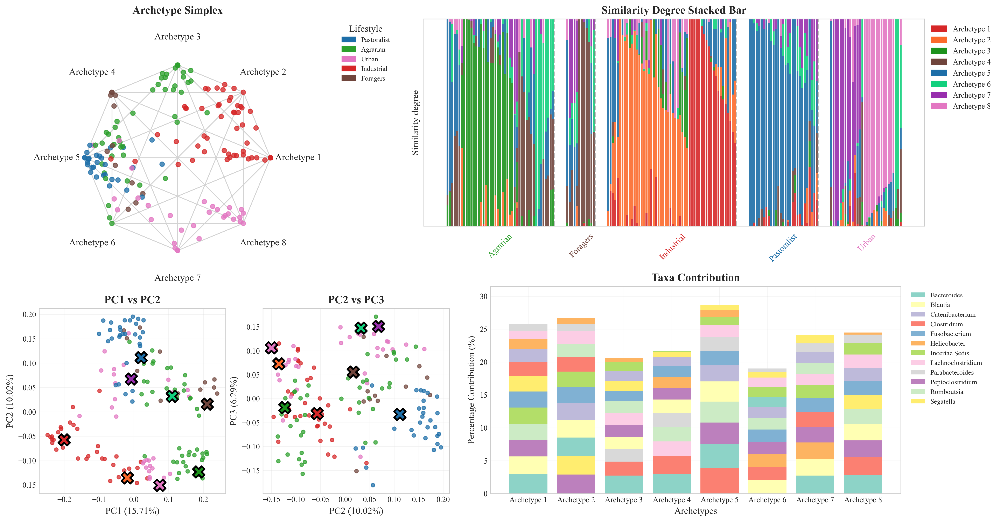

In [29]:
CONSOLIDATED_LAYOUT_DEFAULTS = {

    "figsize": (18, 10),
    "left_height_ratios": [3.0, 2.0],
    "right_height_ratios": [1.0, 1.0],
    "width_ratios": [1, 1.0],
    "wspace": 0.1,
    "left_hspace": 0.05,
    "right_hspace": 0.29,
    "pcoa_wspace": 0.2,
    "simplex_x_offset": -0.06,
    "simplex_width_scale": 1.0,
    "stacked_x_offset": -0.06,
    "stacked_width_scale": 1.22,
}
# Example usage:

plot_consolidated_figure(
    DATASET_CONFIGS["dog"],
    layout_cfg=CONSOLIDATED_LAYOUT_DEFAULTS,
    save_figure=True,
)

/var/folders/px/v6h_m_713lg54rd8cj7pmkz00000gn/T/ipykernel_81146/484205042.py:129: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  fallback_cmap = cm.get_cmap(panel_cmap, len(labels_for_colors))
/var/folders/px/v6h_m_713lg54rd8cj7pmkz00000gn/T/ipykernel_81146/484205042.py:304: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  arch_cmap = cm.get_cmap(pcoa_cmap)
/var/folders/px/v6h_m_713lg54rd8cj7pmkz00000gn/T/ipykernel_81146/484205042.py:347: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


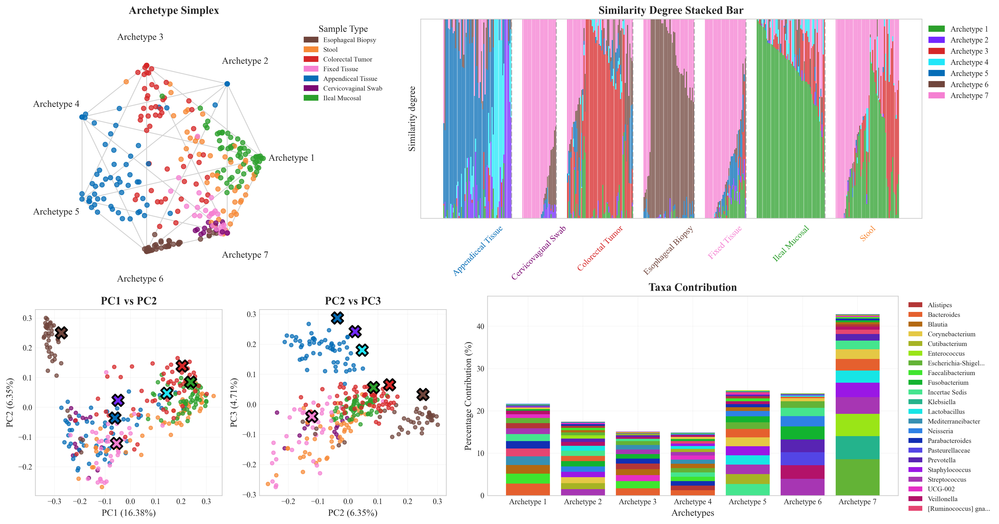

In [30]:
CONSOLIDATED_LAYOUT_DEFAULTS = {

    "figsize": (18, 10),
    "left_height_ratios": [3.0, 2.0],
    "right_height_ratios": [1.0, 1.0],
    "width_ratios": [1, 1.0],
    "wspace": 0.1,
    "left_hspace": 0.05,
    "right_hspace": 0.39,
    "pcoa_wspace": 0.2,
    "simplex_x_offset": -0.06,
    "simplex_width_scale": 1.0,
    "stacked_x_offset": -0.06,
    "stacked_width_scale": 1.22,
}
# Example usage:

plot_consolidated_figure(
    DATASET_CONFIGS["sample_type"],
    layout_cfg=CONSOLIDATED_LAYOUT_DEFAULTS,
    save_figure=True,
)

/var/folders/px/v6h_m_713lg54rd8cj7pmkz00000gn/T/ipykernel_81146/839164312.py:40: DtypeWarning: Columns (0: AGE_MONTHS, 1: SUBJECT_ID, 2: Sample, 3: Age, 4: GENDER, 5: AGE, 6: BREASTFEEDING, 7: RECALL_72H.BAOBAB, 8: RECALL_72H.BERRIES, 9: RECALL_72H.HONEY, 10: RECALL_72H.MAIZE, 11: RECALL_72H.MEAT, 12: RECALL_72H.MILLET, 13: RECALL_72H.TUBERS, 14: RECALL_PRIMARY_FOOD_72H, 15: SLEEPS_WITH_MOTHER, 16: WATER_SOURCE, 17: WEIGHT_KGS, 18: BMI, 19: TWO_SEASON, 20: FOUR_SEASON_YEAR, 21: TWO_SEASON_YEAR, 22: gest_time, 23: Exclusive_breast_feeding, 24: Breast_feeding_end, 25: Regular_formula, 26: hydrosylated_formula, 27: partly_hydrosylated_formula, 28: Any_baby_formula, 29: Fruits_and_berries, 30: Corn, 31: Rice, 32: Wheat, 33: Oat, 34: Barley, 35: Rye, 36: Cereal, 37: Other_grains, 38: Root_vegetables, 39: Vegetables, 40: Eggs, 41: Soy, 42: Milk, 43: Meat, 44: Fish, 45: Other_food, 46: Other_than_BF, 47: bf_length, 48: after_abx, 49: num_preceeding_abx, 50: num_aabs, 51: allergy_egg, 52: all

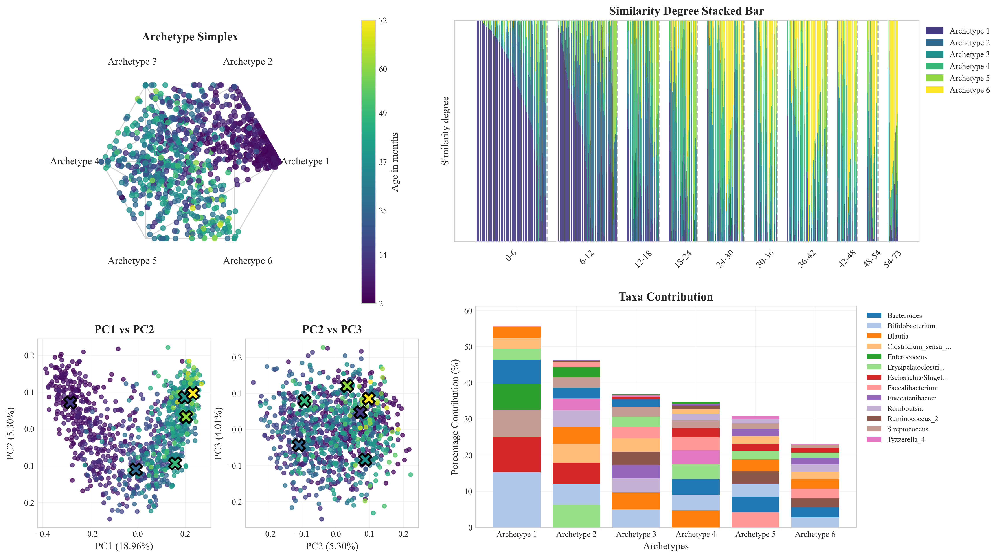

In [31]:
CONSOLIDATED_LAYOUT_DEFAULTS = {

    "figsize": (16, 10),
    "left_height_ratios": [3.0, 2.0],
    "right_height_ratios": [1.0, 1.0],
    "width_ratios": [1, 1.0],
    "wspace": 0.15,
    "left_hspace": 0.15,
    "right_hspace": 0.29,
    "pcoa_wspace": 0.2,
    "simplex_x_offset": 0.0,
    "simplex_width_scale": 1.0,
    "stacked_x_offset": -0.02,
    "stacked_width_scale": 1.22,
}
# Example usage:

plot_consolidated_figure(
    DATASET_CONFIGS["age"],
    layout_cfg=CONSOLIDATED_LAYOUT_DEFAULTS,
    save_figure=True,
)

In [32]:
# load bundles
for dataset_key in DATASET_CONFIGS.keys():
    print(f"Loading bundle for dataset: {dataset_key}")
    bundle = load_dataset_bundle(DATASET_CONFIGS[dataset_key])
    print(f"Bundle for {dataset_key} loaded. Keys: {list(bundle.keys())}")
    # extract top taxa using compositionanalyzer
    comp = CompositionAnalyzer()
    top_taxa = comp.analyze_top_taxa(
        archetypes=np.array(bundle["aa_archetypes"]),
        feature_names=bundle["otu"].columns,
        num_taxa=5,
    )
    # Formats the data as a DataFrame with columns: Archetype, Rank, Taxa, and Abundance
    formatted_data = []
    for archetype_idx, archetype_data in enumerate(top_taxa):
        for rank, (taxa, abundance) in enumerate(archetype_data[:-1], start=1):
            formatted_data.append(
                {
                    "Archetype": f"Archetype {archetype_idx + 1}",
                    "Rank": rank,
                    "Taxa": taxa,
                    "Abundance": abundance,
                }
            )
    df = pd.DataFrame(formatted_data)
    # Save to tsv format in export_dir with appropriate name
    export_path = os.path.join(EXPORT_DIR, f"{dataset_key}_top_taxa.tsv")
    df.to_csv(export_path, sep="\t", index=False)
    print(f"Top taxa for {dataset_key} saved to: {export_path}")

Loading bundle for dataset: dog
Bundle for dog loaded. Keys: ['otu', 'meta', 'projects', 'tags', 'otu_aa', 'aa_labels', 'aa_archetypes', 'info', 'metadata']
Top taxa for dog saved to: ./final_plots/dog_top_taxa.tsv
Loading bundle for dataset: age


/var/folders/px/v6h_m_713lg54rd8cj7pmkz00000gn/T/ipykernel_81146/839164312.py:40: DtypeWarning: Columns (0: AGE_MONTHS, 1: SUBJECT_ID, 2: Sample, 3: Age, 4: GENDER, 5: AGE, 6: BREASTFEEDING, 7: RECALL_72H.BAOBAB, 8: RECALL_72H.BERRIES, 9: RECALL_72H.HONEY, 10: RECALL_72H.MAIZE, 11: RECALL_72H.MEAT, 12: RECALL_72H.MILLET, 13: RECALL_72H.TUBERS, 14: RECALL_PRIMARY_FOOD_72H, 15: SLEEPS_WITH_MOTHER, 16: WATER_SOURCE, 17: WEIGHT_KGS, 18: BMI, 19: TWO_SEASON, 20: FOUR_SEASON_YEAR, 21: TWO_SEASON_YEAR, 22: gest_time, 23: Exclusive_breast_feeding, 24: Breast_feeding_end, 25: Regular_formula, 26: hydrosylated_formula, 27: partly_hydrosylated_formula, 28: Any_baby_formula, 29: Fruits_and_berries, 30: Corn, 31: Rice, 32: Wheat, 33: Oat, 34: Barley, 35: Rye, 36: Cereal, 37: Other_grains, 38: Root_vegetables, 39: Vegetables, 40: Eggs, 41: Soy, 42: Milk, 43: Meat, 44: Fish, 45: Other_food, 46: Other_than_BF, 47: bf_length, 48: after_abx, 49: num_preceeding_abx, 50: num_aabs, 51: allergy_egg, 52: all

Bundle for age loaded. Keys: ['otu', 'meta', 'projects', 'tags', 'otu_aa', 'aa_labels', 'aa_archetypes', 'info', 'metadata']
Top taxa for age saved to: ./final_plots/age_top_taxa.tsv
Loading bundle for dataset: sample_type
Bundle for sample_type loaded. Keys: ['otu', 'meta', 'projects', 'tags', 'otu_aa', 'aa_labels', 'aa_archetypes', 'info', 'metadata']
Top taxa for sample_type saved to: ./final_plots/sample_type_top_taxa.tsv
